<a href="https://colab.research.google.com/github/EmiiFernandez/actividades_data_sciente_ypf/blob/main/notebook/C12_Notebook-16.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

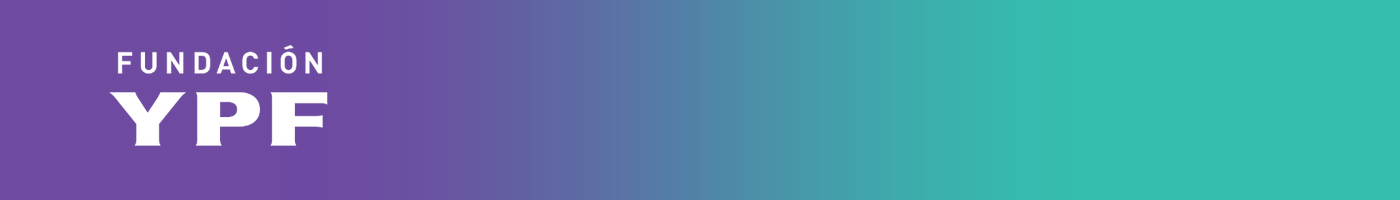

# Fundación YPF - Data Science



# Notebook 16: Regresión y clasificación

## Índice

- **Parte 0** - Repaso: carga, limpieza y preparación del dataset
- **Parte 1** - Regresión vs. clasificación: ¿qué tipo de problema tenemos?
- **Parte 2** - Regresión lineal
- **Parte 3** - Regresión logística
- **Parte 4** - Árboles de decisión
- **Parte 5** - Comparación de modelos
- **Parte 6** - Ejercicio para las salas

---

## Parte 0 - Repaso: carga, limpieza y preparación del dataset

Retomamos el dataset de expectativa de vida que ya usamos en las notebooks 12 y 13. Lo cargamos, limpiamos nombres de columnas, manejamos faltantes y separamos en entrenamiento y test.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder, OrdinalEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, mean_absolute_error, r2_score
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
import warnings
warnings.filterwarnings('ignore')


In [2]:
# Carga del dataset
url = "https://raw.githubusercontent.com/EmiiFernandez/actividades_data_sciente_ypf/main/dataset/"
dataset_life = "life_expectancy_data.csv"
df = pd.read_csv(url+dataset_life)

df.head()

,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,...,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,Afghanistan,2015,Developing,65.0,263.0,62,0.01,71.279624,65.0,1154,...,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,Afghanistan,2014,Developing,59.9,271.0,64,0.01,73.523582,62.0,492,...,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,Afghanistan,2013,Developing,59.9,268.0,66,0.01,73.219243,64.0,430,...,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,Afghanistan,2012,Developing,59.5,272.0,69,0.01,78.184215,67.0,2787,...,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,Afghanistan,2011,Developing,59.2,275.0,71,0.01,7.097109,68.0,3013,...,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5


In [3]:
print(f"Dimensiones: {df.shape}")
df.head()

Dimensiones: (2938, 22)


,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,...,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,Afghanistan,2015,Developing,65.0,263.0,62,0.01,71.279624,65.0,1154,...,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,Afghanistan,2014,Developing,59.9,271.0,64,0.01,73.523582,62.0,492,...,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,Afghanistan,2013,Developing,59.9,268.0,66,0.01,73.219243,64.0,430,...,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,Afghanistan,2012,Developing,59.5,272.0,69,0.01,78.184215,67.0,2787,...,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,Afghanistan,2011,Developing,59.2,275.0,71,0.01,7.097109,68.0,3013,...,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5


In [4]:
# Limpieza de nombres de columnas (quitar espacios al inicio y al final)
df.columns = df.columns.str.strip()
df.columns = df.columns.str.replace(" ", "_")
print("Columnas limpias:")
print(df.columns.tolist())

Columnas limpias:
['Country', 'Year', 'Status', 'Life_expectancy', 'Adult_Mortality', 'infant_deaths', 'Alcohol', 'percentage_expenditure', 'Hepatitis_B', 'Measles', 'BMI', 'under-five_deaths', 'Polio', 'Total_expenditure', 'Diphtheria', 'HIV/AIDS', 'GDP', 'Population', 'thinness__1-19_years', 'thinness_5-9_years', 'Income_composition_of_resources', 'Schooling']


In [5]:
# Revisión de faltantes
print("\nFaltantes por columna:")
print(df.isnull().sum()[df.isnull().sum() > 0])


Faltantes por columna:
Life_expectancy                     10
Adult_Mortality                     10
Alcohol                            194
Hepatitis_B                        553
BMI                                 34
Polio                               19
Total_expenditure                  226
Diphtheria                          19
GDP                                448
Population                         652
thinness__1-19_years                34
thinness_5-9_years                  34
Income_composition_of_resources    167
Schooling                          163
dtype: int64


In [6]:
# Eliminamos filas donde falte la variable objetivo (Life expectancy)
df = df.dropna(subset=['Life_expectancy'])
print(f"\nFilas después de eliminar faltantes en Life expectancy: {len(df)}")


Filas después de eliminar faltantes en Life expectancy: 2928


In [7]:
# Completamos faltantes numéricos con la mediana
cols_numericas = df.select_dtypes(include=[np.number]).columns
df[cols_numericas] = df[cols_numericas].fillna(df[cols_numericas].median())

In [8]:
# Encoding de la variable Status (Developing / Developed)
from sklearn.preprocessing import LabelEncoder
df['Status'].head()

,Status
0,Developing
1,Developing
2,Developing
3,Developing
4,Developing


In [9]:
le_status = LabelEncoder()
df['Status_encoded'] = le_status.fit_transform(df['Status'])
print(f"\nClases de Status: {le_status.classes_}")
print(f"Encoded: {le_status.transform(le_status.classes_)}")


Clases de Status: ['Developed' 'Developing']
Encoded: [0 1]


In [10]:
# Separación en entrenamiento y test
from sklearn.model_selection import train_test_split

In [11]:
# Definimos las features numéricas que vamos a usar
df.columns = df.columns.str.replace("_", " ")
features = ['Adult Mortality', 'infant deaths', 'Alcohol', 'percentage expenditure',
            'Hepatitis B', 'Measles', 'BMI', 'under-five deaths', 'Polio',
            'Total expenditure', 'Diphtheria', 'HIV/AIDS', 'GDP', 'Population',
            'thinness  1-19 years', 'thinness 5-9 years',
            'Income composition of resources', 'Schooling']

In [12]:
X = df[features]
print(X.head())

   Adult Mortality  infant deaths  Alcohol  percentage expenditure  \
0            263.0             62     0.01               71.279624   
1            271.0             64     0.01               73.523582   
2            268.0             66     0.01               73.219243   
3            272.0             69     0.01               78.184215   
4            275.0             71     0.01                7.097109   

   Hepatitis B  Measles   BMI  under-five deaths  Polio  Total expenditure  \
0         65.0     1154  19.1                 83    6.0               8.16   
1         62.0      492  18.6                 86   58.0               8.18   
2         64.0      430  18.1                 89   62.0               8.13   
3         67.0     2787  17.6                 93   67.0               8.52   
4         68.0     3013  17.2                 97   68.0               7.87   

   Diphtheria  HIV/AIDS         GDP  Population  thinness  1-19 years  \
0        65.0       0.1  584.259210  

In [13]:
print(f"\nFeatures seleccionadas: {len(features)}")
print(f"Observaciones: {len(X)}")


Features seleccionadas: 18
Observaciones: 2928


---

## Parte 1 - Regresión vs. clasificación: ¿qué tipo de problema tenemos?

Sobre el mismo dataset podemos plantear dos preguntas distintas:

1. **Regresión**: ¿cuántos años de expectativa de vida tiene un país? (variable continua)
2. **Clasificación**: ¿el país es "Developed" o "Developing"? (variable categórica)

La elección del tipo de problema define qué algoritmo usar, qué métrica medir y cómo interpretar los resultados.

In [14]:
# Variable objetivo para REGRESIÓN
y_reg = df['Life expectancy']
print("Regresión: predecir Life expectancy (continua)")
print(f"  Rango: {y_reg.min():.1f} a {y_reg.max():.1f} años")
print(f"  Media: {y_reg.mean():.1f} años")

Regresión: predecir Life expectancy (continua)
  Rango: 36.3 a 89.0 años
  Media: 69.2 años


In [15]:
# Variable objetivo para CLASIFICACIÓN
y_clf = df['Status encoded']
print(f"\nClasificación: predecir Status (Developing=0, Developed=1)")
print(f"  Proporción clase mayoritaria: {y_clf.value_counts(normalize=True).max():.3f}")
print(f"  Este es nuestro piso de referencia para clasificación.")
df['Status encoded'].head()


Clasificación: predecir Status (Developing=0, Developed=1)
  Proporción clase mayoritaria: 0.825
  Este es nuestro piso de referencia para clasificación.


,Status encoded
0,1
1,1
2,1
3,1
4,1


In [16]:
# Separamos para ambos problemas
X_train, X_test, y_train_reg, y_test_reg = train_test_split(
    X, y_reg, test_size=0.2, random_state=42
)

In [17]:
# Para clasificación usamos los mismos índices
y_train_clf = y_clf.loc[X_train.index]
y_test_clf = y_clf.loc[X_test.index]

print(f"\nTrain: {len(X_train)} | Test: {len(X_test)}")
print(f"x train: {X_train.index} | x test: {X_test.index}")


Train: 2342 | Test: 586
x train: Index([2268, 1680, 2785, 2512, 1090, 1851, 2680, 2237, 1101,  542,
       ...
       1484,  330, 1240,  466, 2177, 1640, 1097, 1132, 1296,  862],
      dtype='int64', length=2342) | x test: Index([2399,  196, 2316, 1735, 1102, 1194, 1507, 1161,  322, 1352,
       ...
       2660, 2275,  456,  462, 2174, 2452,  381, 1784,  964, 1945],
      dtype='int64', length=586)


In [18]:
print(f"\nTrain: {len(X_train)} | Test: {len(X_test)}")


Train: 2342 | Test: 586


In [19]:
# Escalado: ajustamos SOLO con train
from sklearn.preprocessing import StandardScaler

In [20]:
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=features,
    index=X_train.index
)
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    columns=features,
    index=X_test.index
)

In [21]:
print("Escalado ajustado con train y aplicado a test (buena práctica de clase 8).")

Escalado ajustado con train y aplicado a test (buena práctica de clase 8).


---

## Parte 2 - Regresión lineal

Regresión lineal busca la recta (o hiperplano) Y = m1*x1 + m2*x2 + ... + b que minimiza el error cuadrático medio sobre los datos de entrenamiento.

**Supuestos** (repaso de la clase):
- Relación lineal entre X e Y
- Residuos con distribución normal
- Homocedasticidad (varianza constante de los residuos)
- No multicolinealidad

In [22]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.dummy import DummyRegressor

In [23]:
# Piso de referencia para regresión
dummy_reg = DummyRegressor(strategy='mean')
dummy_reg.fit(X_train_scaled, y_train_reg)
y_pred_dummy = dummy_reg.predict(X_test_scaled)

In [24]:
mae_dummy = mean_absolute_error(y_test_reg, y_pred_dummy)
r2_dummy = r2_score(y_test_reg, y_pred_dummy)
print(f"Piso de referencia (predecir la media):")
print(f"  MAE: {mae_dummy:.2f} años")
print(f"  R²:  {r2_dummy:.4f}")

Piso de referencia (predecir la media):
  MAE: 7.68 años
  R²:  -0.0017


In [25]:
# Regresión lineal
lr = LinearRegression()
lr.fit(X_train_scaled, y_train_reg)
y_pred_lr = lr.predict(X_test_scaled)

In [26]:
mae_lr = mean_absolute_error(y_test_reg, y_pred_lr)
r2_lr = r2_score(y_test_reg, y_pred_lr)
print(f"\nRegresión lineal:")
print(f"  MAE: {mae_lr:.2f} años")
print(f"  R²:  {r2_lr:.4f}")


Regresión lineal:
  MAE: 2.96 años
  R²:  0.8155


Text(0.5, 1.0, 'Regresión Lineal: predicho vs. real')

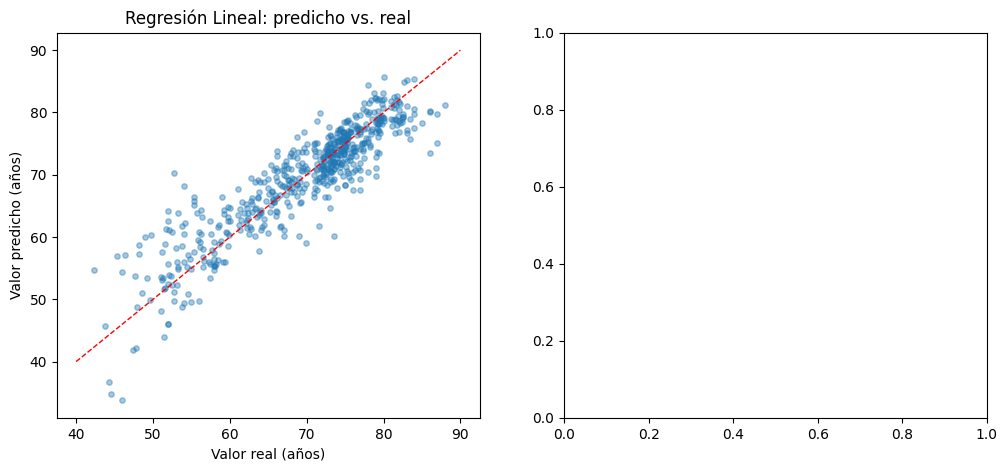

In [27]:
# Visualización: predicho vs. real
fig, axes = plt.subplots(1, 2, figsize=(12, 5))


axes[0].scatter(y_test_reg, y_pred_lr, alpha=0.4, s=15)
axes[0].plot([40, 90], [40, 90], 'r--', lw=1)
axes[0].set_xlabel('Valor real (años)')
axes[0].set_ylabel('Valor predicho (años)')
axes[0].set_title('Regresión Lineal: predicho vs. real')

In [28]:
# Distribución de residuos
residuos = y_test_reg - y_pred_lr
axes[1].hist(residuos, bins=30, edgecolor='black', alpha=0.7)
axes[1].set_xlabel('Residuo (años)')
axes[1].set_ylabel('Frecuencia')
axes[1].set_title('Distribución de los residuos')
axes[1].axvline(x=0, color='r', linestyle='--', lw=1)

In [29]:
plt.tight_layout()
plt.show()

<Figure size 640x480 with 0 Axes>

In [30]:
print(f"\nLos 5 features con mayor peso (valor absoluto):")
coefs = pd.Series(lr.coef_, index=features).abs().sort_values(ascending=False)
print(coefs.head())


Los 5 features con mayor peso (valor absoluto):
under-five deaths    11.326072
infant deaths        11.191197
Adult Mortality       2.594586
HIV/AIDS              2.489641
Schooling             2.174925
dtype: float64


---

## Parte 3 - Regresión logística

Pese a su nombre, regresión logística es un algoritmo de **clasificación**. Usa la función sigmoide para transformar la salida de una combinación lineal en una probabilidad entre 0 y 1.

**Supuestos:**
- Linealidad entre las features y el log-odds
- Independencia de observaciones
- No multicolinealidad
- Tamaño de muestra suficiente

In [31]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.dummy import DummyClassifier

In [32]:
# Piso de referencia para clasificación
dummy_clf = DummyClassifier(strategy='most_frequent')
dummy_clf.fit(X_train_scaled, y_train_clf)
y_pred_dummy_clf = dummy_clf.predict(X_test_scaled)

In [33]:
acc_dummy = accuracy_score(y_test_clf, y_pred_dummy_clf)
print(f"Piso de referencia (predecir la clase mayoritaria):")
print(f"  Exactitud: {acc_dummy:.3f}")

Piso de referencia (predecir la clase mayoritaria):
  Exactitud: 0.817


In [34]:
# Regresión logística
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_scaled, y_train_clf)
y_pred_log = log_reg.predict(X_test_scaled)

In [35]:
acc_log = accuracy_score(y_test_clf, y_pred_log)
print(f"\nRegresión logística:")
print(f"  Exactitud: {acc_log:.3f}")
print(f"\nReporte de clasificación:")
print(classification_report(y_test_clf, y_pred_log, target_names=le_status.classes_))


Regresión logística:
  Exactitud: 0.928

Reporte de clasificación:
              precision    recall  f1-score   support

   Developed       0.79      0.82      0.81       107
  Developing       0.96      0.95      0.96       479

    accuracy                           0.93       586
   macro avg       0.88      0.89      0.88       586
weighted avg       0.93      0.93      0.93       586



In [36]:
# Matriz de confusión
from sklearn.metrics import ConfusionMatrixDisplay

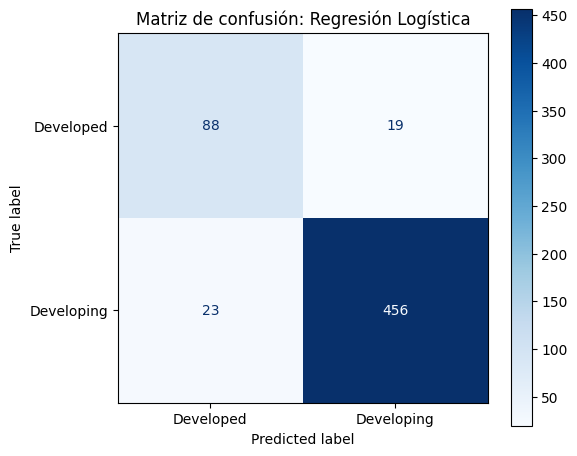

In [37]:
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_estimator(
    log_reg, X_test_scaled, y_test_clf,
    display_labels=le_status.classes_, ax=ax, cmap='Blues'
)
ax.set_title('Matriz de confusión: Regresión Logística')
plt.tight_layout()
plt.show()

In [38]:
# Probabilidades predichas
y_proba = log_reg.predict_proba(X_test_scaled)[:, 1]
print(f"\nEjemplo de probabilidades predichas (primeras 10):")
print(np.round(y_proba[:10], 3))
print("Si la probabilidad es mayor a 0.5, se clasifica como 'Developed'.")


Ejemplo de probabilidades predichas (primeras 10):
[1.    1.    0.564 0.987 1.    1.    0.997 0.243 0.846 0.918]
Si la probabilidad es mayor a 0.5, se clasifica como 'Developed'.


---

## Parte 4 - Árboles de decisión

Los árboles de decisión funcionan tanto para clasificación como para regresión. Hacen preguntas binarias sobre las features y dividen los datos en subgrupos cada vez más homogéneos.

**Ventajas:** interpretables, no asumen linealidad, manejan relaciones complejas.
**Riesgo:** tienden al sobreajuste si no se controlan con max_depth o min_samples.

In [39]:
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree

In [40]:
# --- Árbol para CLASIFICACIÓN ---
tree_clf = DecisionTreeClassifier(max_depth=3, random_state=42)
tree_clf.fit(X_train_scaled, y_train_clf)
y_pred_tree_clf = tree_clf.predict(X_test_scaled)

In [41]:
acc_tree = accuracy_score(y_test_clf, y_pred_tree_clf)
print(f"Árbol de clasificación (max_depth=3):")
print(f"  Exactitud: {acc_tree:.3f}")

Árbol de clasificación (max_depth=3):
  Exactitud: 0.935


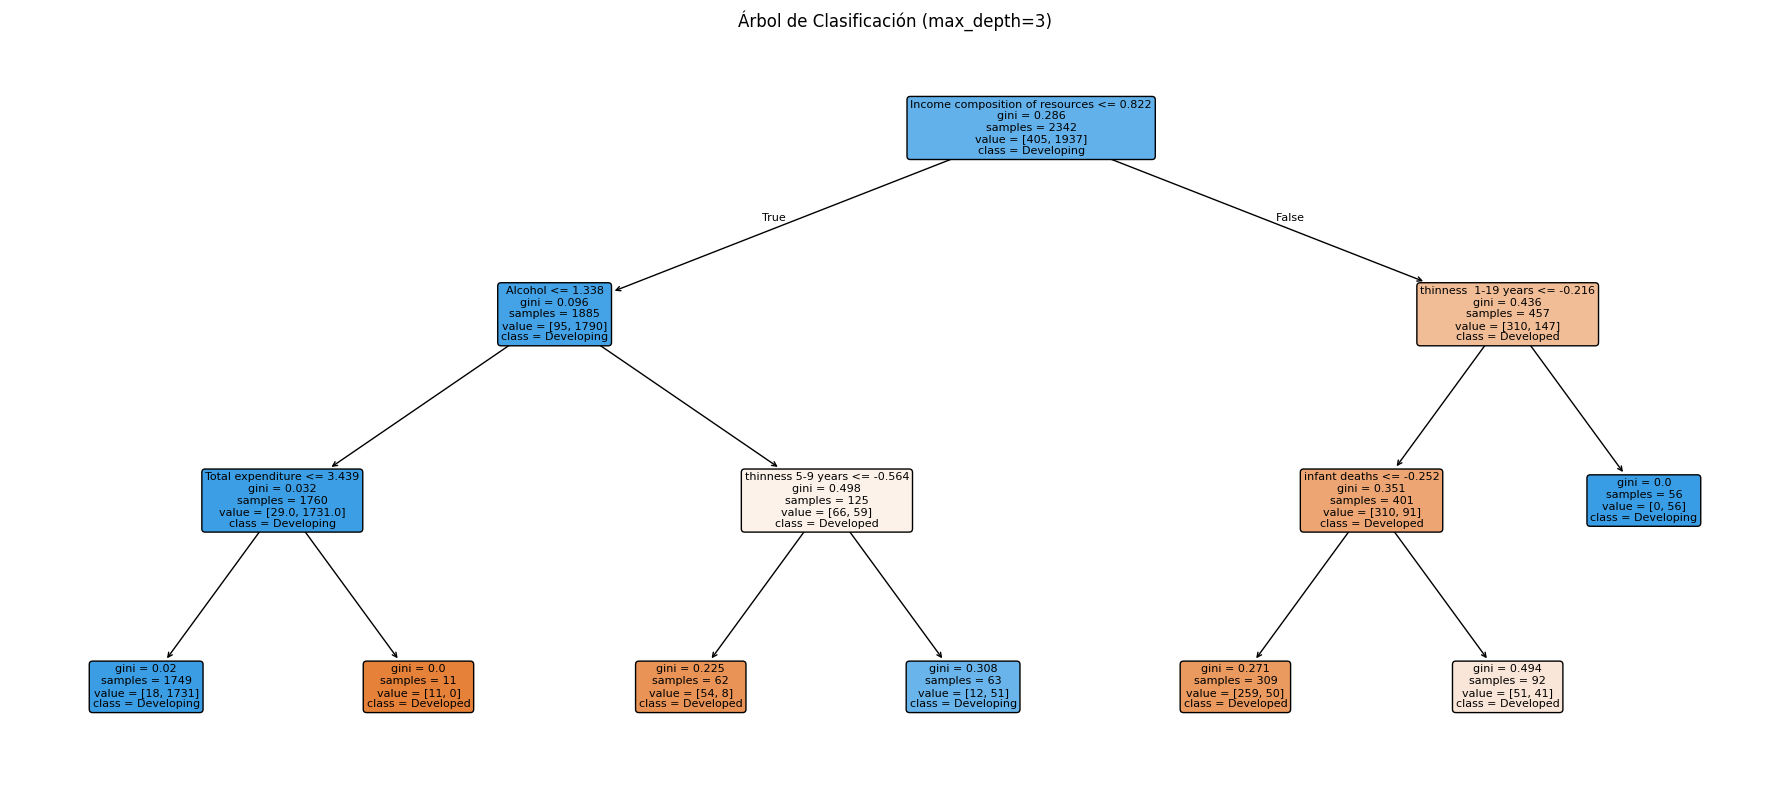

In [42]:
# Visualización del árbol
fig, ax = plt.subplots(figsize=(18, 8))
plot_tree(tree_clf, feature_names=features, class_names=le_status.classes_,
          filled=True, rounded=True, ax=ax, fontsize=8)
ax.set_title('Árbol de Clasificación (max_depth=3)')
plt.tight_layout()
plt.show()

In [43]:
# --- Árbol para REGRESIÓN ---
tree_reg = DecisionTreeRegressor(max_depth=4, random_state=42)
tree_reg.fit(X_train_scaled, y_train_reg)
y_pred_tree_reg = tree_reg.predict(X_test_scaled)

In [44]:
mae_tree = mean_absolute_error(y_test_reg, y_pred_tree_reg)
r2_tree = r2_score(y_test_reg, y_pred_tree_reg)
print(f"\nÁrbol de regresión (max_depth=4):")
print(f"  MAE: {mae_tree:.2f} años")
print(f"  R²:  {r2_tree:.4f}")


Árbol de regresión (max_depth=4):
  MAE: 2.59 años
  R²:  0.8604


### Sobreajuste en árboles

Un árbol sin límite de profundidad memoriza los datos de entrenamiento. Veamos cómo cambia el rendimiento al aumentar la profundidad.

In [45]:
# Efecto de la profundidad sobre train y test
profundidades = range(1, 21)
acc_train_list = []
acc_test_list = []

In [46]:
for d in profundidades:
    tree_temp = DecisionTreeClassifier(max_depth=d, random_state=42)
    tree_temp.fit(X_train_scaled, y_train_clf)
    acc_train_list.append(accuracy_score(y_train_clf, tree_temp.predict(X_train_scaled)))
    acc_test_list.append(accuracy_score(y_test_clf, tree_temp.predict(X_test_scaled)))

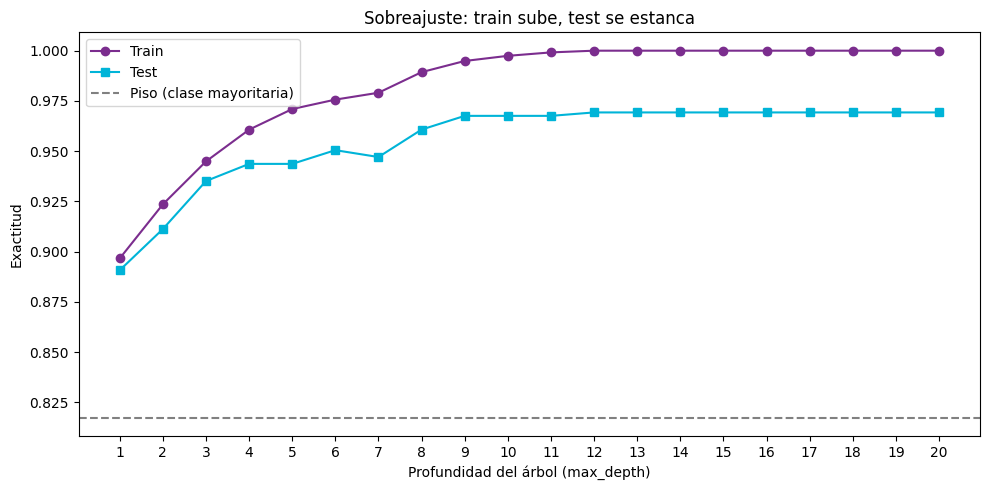

In [47]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(profundidades, acc_train_list, 'o-', label='Train', color='#7B2D8E')
ax.plot(profundidades, acc_test_list, 's-', label='Test', color='#00B4D8')
ax.axhline(y=acc_dummy, color='gray', linestyle='--', label='Piso (clase mayoritaria)')
ax.set_xlabel('Profundidad del árbol (max_depth)')
ax.set_ylabel('Exactitud')
ax.set_title('Sobreajuste: train sube, test se estanca')
ax.legend()
ax.set_xticks(range(1, 21))
plt.tight_layout()
plt.show()

In [48]:
print("Cuando la exactitud en train sube mucho más que en test, el modelo está memorizando.")
print("max_depth y min_samples_leaf son herramientas para controlarlo.")

Cuando la exactitud en train sube mucho más que en test, el modelo está memorizando.
max_depth y min_samples_leaf son herramientas para controlarlo.


---

## Parte 5 - Comparación de modelos

Reunimos los resultados de todos los modelos en una tabla para facilitar la comparación.

In [49]:
# Tabla de comparación para CLASIFICACIÓN
print("=" * 55)
print("CLASIFICACIÓN: ¿Developing o Developed?")
print("=" * 55)
print(f"{'Modelo':<30} {'Exactitud':>10}")
print("-" * 55)
print(f"{'Piso (clase mayoritaria)':<30} {acc_dummy:>10.3f}")
print(f"{'Regresión logística':<30} {acc_log:>10.3f}")
print(f"{'Árbol de decisión (depth=3)':<30} {acc_tree:>10.3f}")
print()

CLASIFICACIÓN: ¿Developing o Developed?
Modelo                          Exactitud
-------------------------------------------------------
Piso (clase mayoritaria)            0.817
Regresión logística                 0.928
Árbol de decisión (depth=3)         0.935



In [50]:
# Tabla de comparación para REGRESIÓN
print("=" * 55)
print("REGRESIÓN: ¿Cuántos años de expectativa de vida?")
print("=" * 55)
print(f"{'Modelo':<30} {'MAE (años)':>10} {'R²':>10}")
print("-" * 55)
print(f"{'Piso (predecir la media)':<30} {mae_dummy:>10.2f} {r2_dummy:>10.4f}")
print(f"{'Regresión lineal':<30} {mae_lr:>10.2f} {r2_lr:>10.4f}")
print(f"{'Árbol de regresión (depth=4)':<30} {mae_tree:>10.2f} {r2_tree:>10.4f}")

REGRESIÓN: ¿Cuántos años de expectativa de vida?
Modelo                         MAE (años)         R²
-------------------------------------------------------
Piso (predecir la media)             7.68    -0.0017
Regresión lineal                     2.96     0.8155
Árbol de regresión (depth=4)         2.59     0.8604


### Observaciones clave

- Todos los modelos superan al piso de referencia, lo cual confirma que están aprendiendo patrones reales.
- Regresión logística y el árbol de clasificación tienen rendimientos cercanos, pero el árbol es más interpretable (podemos ver las reglas de decisión).
- En regresión, la regresión lineal captura la tendencia general pero los residuos muestran que hay relaciones que no son estrictamente lineales. El árbol puede capturar relaciones no lineales, pero con riesgo de sobreajuste.
- La elección del algoritmo no es solo por el rendimiento: la interpretabilidad, los supuestos y el contexto del problema también importan.

---

## Parte 6 - Ejercicio para las salas

**Dataset:** `cancer_mamario.csv`

**Objetivo:** Predecir si un caso de cáncer mamario tuvo recurrencia o no (`class`: "recurrence-events" / "no-recurrence-events").

**Tiempo sugerido:** 40 minutos.

### Pasos

1. **Exploración** (10 min): cargar el dataset, revisar las columnas, identificar faltantes y tipos de datos. ¿Es un problema de regresión o de clasificación?

2. **Preparación** (10 min): hacer el encoding de las variables categóricas, manejar faltantes si los hay, separar en train y test.

3. **Modelado** (10 min): entrenar al menos dos modelos de los vistos en clase (regresión logística y/o árbol de decisión). Calcular el piso con DummyClassifier.

4. **Comparación** (10 min): armar una tabla con los resultados. ¿Qué modelo funcionó mejor? ¿Cómo se compara con el piso? ¿Hay sobreajuste?

### Pistas

- Las columnas de este dataset son todas categóricas (rangos de edad, tamaño de tumor, etc.), excepto `deg-malig`. Van a necesitar encoding (OrdinalEncoder o pd.get_dummies).
- Cuidado con los valores faltantes: algunas columnas pueden tener "?" en lugar de NaN.
- El dataset es chico (286 filas), así que el tamaño de muestra importa. Tengan en cuenta esto al elegir modelos y al interpretar métricas.

### Errores frecuentes a evitar

- Escalar o ajustar cualquier transformación con todo el dataset en vez de solo con train.
- No comparar contra un piso de referencia: sin piso no se sabe si el modelo aprendió algo.
- Usar un árbol sin limitar la profundidad: con un dataset chico, va a memorizar casi seguro.

In [51]:
dataset_cancer = "cancer_mamario.csv"
cancer_mamario = pd.read_csv(url+dataset_cancer)
df_cancer = cancer_mamario.copy()


In [52]:
df_cancer.head()

,class,age,menopause,tumor-size,inv-nodes,node-caps,deg-malig,breast,breast-quad,irradiat
0,no-recurrence-events,30-39,premeno,30-34,0-2,no,3,left,left_low,no
1,no-recurrence-events,40-49,premeno,20-24,0-2,no,2,right,right_up,no
2,no-recurrence-events,40-49,premeno,20-24,0-2,no,2,left,left_low,no
3,no-recurrence-events,60-69,ge40,15-19,0-2,no,2,right,left_up,no
4,no-recurrence-events,40-49,premeno,0-4,0-2,no,2,right,right_low,no


In [53]:
print('Filas y columnas:', df_cancer.shape)
df_cancer.info()

Filas y columnas: (286, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 286 entries, 0 to 285
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   class        286 non-null    object
 1   age          286 non-null    object
 2   menopause    286 non-null    object
 3   tumor-size   286 non-null    object
 4   inv-nodes    286 non-null    object
 5   node-caps    286 non-null    object
 6   deg-malig    286 non-null    int64 
 7   breast       286 non-null    object
 8   breast-quad  286 non-null    object
 9   irradiat     286 non-null    object
dtypes: int64(1), object(9)
memory usage: 22.5+ KB


In [54]:
df_cancer.columns = df_cancer.columns.str.strip()
df_cancer = df_cancer.drop_duplicates()
print("Sin duplicados:", df_cancer.shape)

Sin duplicados: (272, 10)


In [55]:
marcadores = ["?", "", " ", "-", "NA", "N/A", "nan", "null", "None", "unknown"]
s = df_cancer.astype(str).apply(lambda c: c.str.strip())
print(s.isin(marcadores).sum())

for col in df_cancer.columns:
    print(f"\n--- {col} ---")
    print(df_cancer[col].value_counts(dropna=False))

class          0
age            0
menopause      0
tumor-size     0
inv-nodes      0
node-caps      8
deg-malig      0
breast         0
breast-quad    1
irradiat       0
dtype: int64

--- class ---
class
no-recurrence-events    191
recurrence-events        81
Name: count, dtype: int64

--- age ---
age
50-59    91
40-49    87
60-69    53
30-39    34
70-79     6
20-29     1
Name: count, dtype: int64

--- menopause ---
menopause
premeno    143
ge40       122
lt40         7
Name: count, dtype: int64

--- tumor-size ---
tumor-size
30-34    60
25-29    51
20-24    47
15-19    26
10-14    26
40-44    21
35-39    18
50-54     8
0-4       8
5-9       4
45-49     3
Name: count, dtype: int64

--- inv-nodes ---
inv-nodes
0-2      200
3-5       36
6-8       16
9-11      10
15-17      6
12-14      3
24-26      1
Name: count, dtype: int64

--- node-caps ---
node-caps
no     209
yes     55
?        8
Name: count, dtype: int64

--- deg-malig ---
deg-malig
2    124
3     82
1     66
Name: count, dtype: 

In [56]:
# Los faltantes vienen como "?": los convertimos en NaN
df_cancer = df_cancer.replace("?", np.nan)
print(df_cancer.isna().sum())

class          0
age            0
menopause      0
tumor-size     0
inv-nodes      0
node-caps      8
deg-malig      0
breast         0
breast-quad    1
irradiat       0
dtype: int64


In [57]:
# node-caps: repartir los faltantes entre "no" y "yes" según su proporción
proporciones = df_cancer["node-caps"].value_counts(normalize=True)
faltantes = df_cancer["node-caps"].isna()
rng = np.random.default_rng(42)
df_cancer.loc[faltantes, "node-caps"] = rng.choice(
    proporciones.index, size=faltantes.sum(), p=proporciones.values
)

# breast-quad: rellenar con el valor más frecuente
df_cancer["breast-quad"] = df_cancer["breast-quad"].fillna(df_cancer["breast-quad"].mode()[0])

print("Faltantes restantes:", df_cancer.isna().sum().sum())   # tiene que dar 0

Faltantes restantes: 0


Estrategia de imputación:
- node-caps: el 79% de los valores conocidos son “no” y el 21% “yes”. Los 8 faltantes se sortean respetando esa proporción, y quedaron 6 “no” y 2 “yes”. Si se hubiera usado la moda, los 8 serían “no” y se exageraría esa categoría.
- breast-quad: como hay un solo faltante, se usa la moda directamente.

In [58]:
# Objetivo y las variables de entrada

le_status = LabelEncoder()
df_cancer["class_encoded"] = le_status.fit_transform(df_cancer["class"])
print("Clases:", le_status.classes_, "->", le_status.transform(le_status.classes_))

y_cancer = df_cancer["class_encoded"]
print(y_cancer.value_counts())

# El objetivo sale de X en sus dos versiones (texto y codificada)
X_cancer = df_cancer.drop(columns=["class", "class_encoded"])
print(X_cancer.columns.tolist())

Clases: ['no-recurrence-events' 'recurrence-events'] -> [0 1]
class_encoded
0    191
1     81
Name: count, dtype: int64
['age', 'menopause', 'tumor-size', 'inv-nodes', 'node-caps', 'deg-malig', 'breast', 'breast-quad', 'irradiat']


Es un problema de clasificación, porque la respuesta es una categoría.

Las clases están desbalanceadas: hay más del doble de casos sin recurrencia.

In [59]:
# Separar entrenamiento y test
X_cancer_train, X_cancer_test, y_cancer_train, y_cancer_test = train_test_split(
    X_cancer, y_cancer, test_size=0.2, random_state=42, stratify=y_cancer
)
X_cancer_train = X_cancer_train.copy()
X_cancer_test = X_cancer_test.copy()

print(f"Train: {len(X_cancer_train)} | Test: {len(X_cancer_test)}")
print(f"Recurrencia en train: {y_cancer_train.mean():.1%} | en test: {y_cancer_test.mean():.1%}")

Train: 217 | Test: 55
Recurrencia en train: 30.0% | en test: 29.1%


In [60]:
# Convertir las variables a números

# Ordinales: rangos con orden real
ordinales = ["age", "tumor-size", "inv-nodes", "deg-malig"]
categorias = [
    sorted(X_cancer[col].unique(), key=lambda v: int(str(v).split("-")[0]))
    for col in ordinales
]
enc = OrdinalEncoder(categories=categorias)
X_cancer_train[ordinales] = enc.fit_transform(X_cancer_train[ordinales])
X_cancer_test[ordinales] = enc.transform(X_cancer_test[ordinales])

# Binarias: 0/1
binarias = {"node-caps": "yes", "breast": "right", "irradiat": "yes"}
for col, positivo in binarias.items():
    X_cancer_train[col] = (X_cancer_train[col] == positivo).astype(int)
    X_cancer_test[col] = (X_cancer_test[col] == positivo).astype(int)

# Nominales (sin orden): one-hot
nominales = ["menopause", "breast-quad"]
X_cancer_train = pd.get_dummies(X_cancer_train, columns=nominales, drop_first=True, dtype=int)
X_cancer_test = pd.get_dummies(X_cancer_test, columns=nominales, drop_first=True, dtype=int)
X_cancer_test = X_cancer_test.reindex(columns=X_cancer_train.columns, fill_value=0)

features_cancer = X_cancer_train.columns.tolist()
print(f"{len(features_cancer)} variables:", features_cancer)

13 variables: ['age', 'tumor-size', 'inv-nodes', 'node-caps', 'deg-malig', 'breast', 'irradiat', 'menopause_lt40', 'menopause_premeno', 'breast-quad_left_low', 'breast-quad_left_up', 'breast-quad_right_low', 'breast-quad_right_up']


In [61]:
# Escalar

scaler_cancer = StandardScaler()
X_cancer_train_scaled = pd.DataFrame(
    scaler_cancer.fit_transform(X_cancer_train),
    columns=features_cancer, index=X_cancer_train.index
)
X_cancer_test_scaled = pd.DataFrame(
    scaler_cancer.transform(X_cancer_test),
    columns=features_cancer, index=X_cancer_test.index
)

In [62]:
#Piso
dummy_cancer = DummyClassifier(strategy="most_frequent")
dummy_cancer.fit(X_cancer_train_scaled, y_cancer_train)
acc_dummy = accuracy_score(y_cancer_test, dummy_cancer.predict(X_cancer_test_scaled))

In [63]:
# Regresión logística
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_cancer_train_scaled, y_cancer_train)
y_cancer_pred_log = log_reg.predict(X_cancer_test_scaled)
acc_log = accuracy_score(y_cancer_test, y_cancer_pred_log)


In [64]:
nombres_clases = le_status.classes_
print(f"Piso (siempre 'no recurre'): {acc_dummy:.1%}")
print(f"Regresión logística:         {acc_log:.1%}")
print(f"Diferencia:                  {acc_log - acc_dummy:+.1%}\n")
print(classification_report(y_cancer_test, y_cancer_pred_log, target_names=nombres_clases))

Piso (siempre 'no recurre'): 70.9%
Regresión logística:         78.2%
Diferencia:                  +7.3%

                      precision    recall  f1-score   support

no-recurrence-events       0.80      0.92      0.86        39
   recurrence-events       0.70      0.44      0.54        16

            accuracy                           0.78        55
           macro avg       0.75      0.68      0.70        55
        weighted avg       0.77      0.78      0.76        55



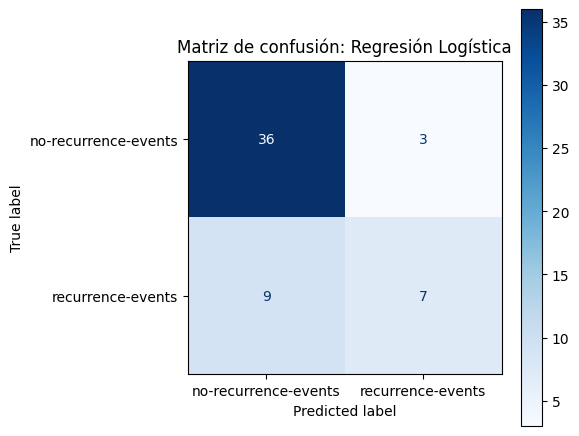

Probabilidad de recurrencia (primeras 10): [0.282 0.14  0.42  0.238 0.298 0.228 0.167 0.165 0.311 0.541]
Si la probabilidad es mayor a 0.5, se clasifica como 'recurrence-events'.


In [65]:
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_estimator(
    log_reg, X_cancer_test_scaled, y_cancer_test,
    display_labels=nombres_clases, ax=ax, cmap="Blues"
)
ax.set_title("Matriz de confusión: Regresión Logística")
plt.tight_layout()
plt.show()

y_cancer_proba = log_reg.predict_proba(X_cancer_test_scaled)[:, 1]
print("Probabilidad de recurrencia (primeras 10):", np.round(y_cancer_proba[:10], 3))
print("Si la probabilidad es mayor a 0.5, se clasifica como 'recurrence-events'.")

Árbol de decisión

In [66]:
# --- Árbol para CLASIFICACIÓN ---
tree_cm = DecisionTreeClassifier(max_depth=3, random_state=42)
tree_cm.fit(X_cancer_train_scaled, y_cancer_train)
y_pred_tree_cm = tree_cm.predict(X_cancer_test_scaled)

In [67]:
acc_tree_cm = accuracy_score(y_cancer_test, y_pred_tree_cm)
print(f"Árbol de clasificación (max_depth=3):")
print(f"  Exactitud: {acc_tree:.3f}")

Árbol de clasificación (max_depth=3):
  Exactitud: 0.935


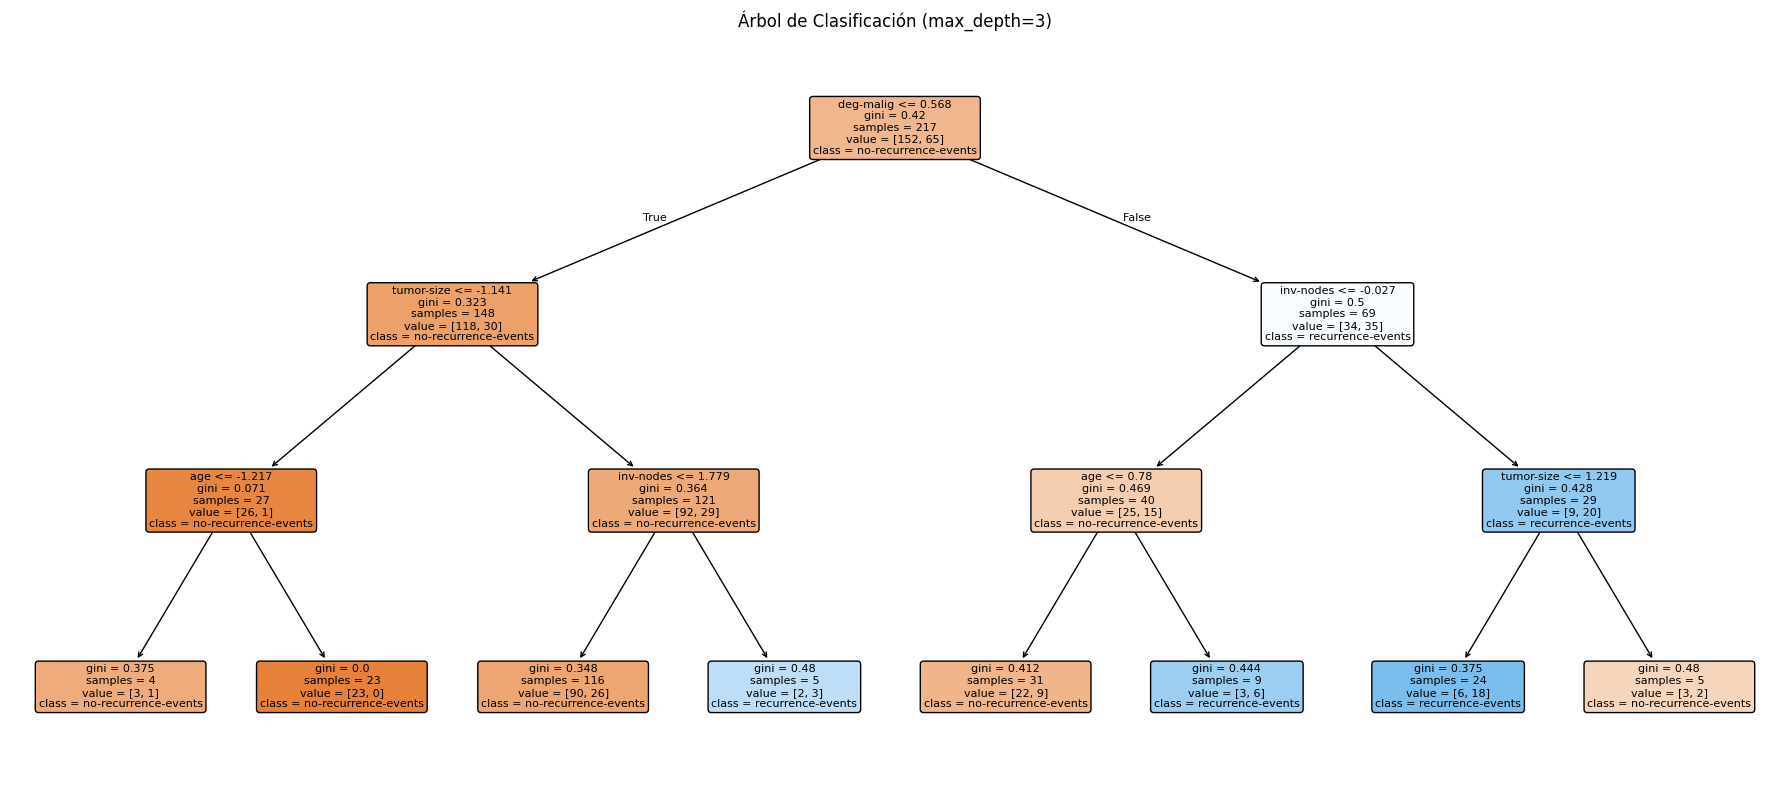

In [68]:
# Visualización del árbol
fig, ax = plt.subplots(figsize=(18, 8))
plot_tree(tree_cm, feature_names=features_cancer, class_names=nombres_clases,
          filled=True, rounded=True, ax=ax, fontsize=8)
ax.set_title('Árbol de Clasificación (max_depth=3)')
plt.tight_layout()
plt.show()

---

## Anexo: Soluciones sugeridas de la Parte 6

*Si se quiere entregar una versión sin soluciones, borrar desde acá hasta el final del notebook.*

In [69]:
# Carga
#try:
#    df_cancer = pd.read_csv('/content/cancer_mamario.csv')
#except FileNotFoundError:
#    df_cancer = pd.read_csv('cancer_mamario.csv')

In [70]:
print(f"Dimensiones: {df_cancer.shape}")
print(f"\nValores únicos por columna:")
for col in df_cancer.columns:
    print(f"  {col}: {df_cancer[col].nunique()} valores")

Dimensiones: (272, 11)

Valores únicos por columna:
  class: 2 valores
  age: 6 valores
  menopause: 3 valores
  tumor-size: 11 valores
  inv-nodes: 7 valores
  node-caps: 2 valores
  deg-malig: 3 valores
  breast: 2 valores
  breast-quad: 5 valores
  irradiat: 2 valores
  class_encoded: 2 valores


In [71]:
print(f"\nDistribución de la variable objetivo:")
print(df_cancer['class'].value_counts())


Distribución de la variable objetivo:
class
no-recurrence-events    191
recurrence-events        81
Name: count, dtype: int64


In [72]:
# Reemplazar '?' por NaN y manejar faltantes
df_cancer = df_cancer.replace('?', np.nan)
print(f"\nFaltantes después de reemplazar '?':")
print(df_cancer.isnull().sum()[df_cancer.isnull().sum() > 0])


Faltantes después de reemplazar '?':
Series([], dtype: int64)


In [73]:
# Rellenamos faltantes categóricos con la moda
for col in df_cancer.columns:
    if df_cancer[col].isnull().sum() > 0:
        df_cancer[col] = df_cancer[col].fillna(df_cancer[col].mode()[0])

In [74]:
# Encoding de la variable objetivo
y_cancer = (df_cancer['class'] == 'recurrence-events').astype(int)
X_cancer = df_cancer.drop(columns=['class'])

In [75]:
# Encoding de features categóricas con get_dummies
X_cancer = pd.get_dummies(X_cancer, drop_first=True)

In [76]:
print(f"\nFeatures después de encoding: {X_cancer.shape[1]}")


Features después de encoding: 32


In [77]:
# Separación
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_cancer, y_cancer, test_size=0.2, random_state=42, stratify=y_cancer
)

In [78]:
# Escalado (solo para logística, árboles no lo necesitan)
scaler_c = StandardScaler()
X_train_c_scaled = scaler_c.fit_transform(X_train_c)
X_test_c_scaled = scaler_c.transform(X_test_c)

In [79]:
# Piso
dummy_c = DummyClassifier(strategy='most_frequent')
dummy_c.fit(X_train_c_scaled, y_train_c)
acc_piso = accuracy_score(y_test_c, dummy_c.predict(X_test_c_scaled))

In [80]:
# Regresión logística
log_c = LogisticRegression(max_iter=1000, random_state=42)
log_c.fit(X_train_c_scaled, y_train_c)
acc_log_c = accuracy_score(y_test_c, log_c.predict(X_test_c_scaled))

In [81]:
# Árbol de decisión
tree_c = DecisionTreeClassifier(max_depth=3, random_state=42)
tree_c.fit(X_train_c, y_train_c)  # árboles no requieren escalado
acc_tree_c = accuracy_score(y_test_c, tree_c.predict(X_test_c))

In [82]:
# Árbol sin límite (para mostrar sobreajuste)
tree_c_nolimit = DecisionTreeClassifier(random_state=42)
tree_c_nolimit.fit(X_train_c, y_train_c)
acc_tree_nolimit_train = accuracy_score(y_train_c, tree_c_nolimit.predict(X_train_c))
acc_tree_nolimit_test = accuracy_score(y_test_c, tree_c_nolimit.predict(X_test_c))

In [83]:
print("=" * 55)
print("RESULTADOS: Clasificación de recurrencia de cáncer mamario")
print("=" * 55)
print(f"{'Modelo':<35} {'Exactitud test':>15}")
print("-" * 55)
print(f"{'Piso (clase mayoritaria)':<35} {acc_piso:>15.3f}")
print(f"{'Regresión logística':<35} {acc_log_c:>15.3f}")
print(f"{'Árbol (max_depth=3)':<35} {acc_tree_c:>15.3f}")
print(f"{'Árbol (sin límite) - train':<35} {acc_tree_nolimit_train:>15.3f}")
print(f"{'Árbol (sin límite) - test':<35} {acc_tree_nolimit_test:>15.3f}")
print()
print("El árbol sin límite memoriza el train (exactitud ~1.0) pero no mejora en test.")
print("Este dataset es chico y difícil: los modelos no superan al piso por mucho,")
print("lo que indica que las features disponibles tienen poder predictivo limitado.")
print("Esto es un resultado válido y frecuente en datos reales.")

RESULTADOS: Clasificación de recurrencia de cáncer mamario
Modelo                               Exactitud test
-------------------------------------------------------
Piso (clase mayoritaria)                      0.709
Regresión logística                           1.000
Árbol (max_depth=3)                           1.000
Árbol (sin límite) - train                    1.000
Árbol (sin límite) - test                     1.000

El árbol sin límite memoriza el train (exactitud ~1.0) pero no mejora en test.
Este dataset es chico y difícil: los modelos no superan al piso por mucho,
lo que indica que las features disponibles tienen poder predictivo limitado.
Esto es un resultado válido y frecuente en datos reales.
